# Module 1 — Cohérence texte/note

**Projet ReviewScope** | 8INF867 — Apprentissage automatique | UQAC

---

Ce notebook explore la **cohérence entre le texte d'un avis et la note attribuée**.  
L'idée centrale : un classifieur de sentiment entraîné sur la majorité « cohérente » des avis peut servir de **détecteur d'anomalies** en identifiant les cas où le texte contredit la note.

**Approche supervisée — l'anomalie comme signal** :
- On entraîne un classifieur TF-IDF + Logistic Regression sur le sentiment (négatif/neutre/positif)
- Les avis dont le sentiment prédit diverge fortement de la note constituent des **incohérences**
- Un score d'incohérence quantifie cette divergence

**Étapes :**
1. Chargement des données nettoyées
2. Mapping note → sentiment
3. Baseline TF-IDF + LogisticRegression
4. Prédictions cross-validées (hors pli)
5. Identification des avis incohérents
6. Score d'incohérence
7. Top 20 des avis les plus incohérents
8. Placeholder d'annotation manuelle
9. Matrice de confusion
10. Sauvegarde

## 0. Configuration et imports

In [2]:
import sys
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, '..')

import config
from src.data_loader import *
from src.text_processing import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, f1_score
)
from sklearn.pipeline import Pipeline

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f"Projet : {config.PROJECT_ROOT.name}")
print(f"Random state : {config.RANDOM_STATE}")

Projet : projet_aa
Random state : 42


## 1. Chargement des données nettoyées

On charge le fichier `reviews_clean.csv` produit par le **Module 0 (Audit & Nettoyage)**.  
Ce fichier contient déjà les colonnes `DateTime`, `Year`, `SentimentClass`, `HelpfulnessRatio`, etc.

In [3]:
# Chargement
df = pd.read_csv(config.DATA_PROCESSED / 'reviews_clean.csv')
print(f"Données chargées : {len(df):,} avis, {df.shape[1]} colonnes")
print(f"Colonnes : {list(df.columns)}")
print()
df.head(3)

Données chargées : 393,892 avis, 17 colonnes
Colonnes : ['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text', 'DateTime', 'Year', 'Month', 'HasVotes', 'HelpfulnessRatio', 'IsHelpful', 'SentimentClass']



,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,DateTime,Year,Month,HasVotes,HelpfulnessRatio,IsHelpful,SentimentClass
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...,2011-04-27,2011,4,True,1.0,0,positif
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,2012-09-07,2012,9,False,NaN,0,negatif
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...,2008-08-18,2008,8,True,1.0,0,positif


## 2. Mapping note → sentiment

On mappe les 5 niveaux de note vers 3 classes de sentiment :

| Note | Classe |
|------|--------|
| 1, 2 | **négatif** |
| 3    | **neutre** |
| 4, 5 | **positif** |

Ce mapping est défini dans `config.SENTIMENT_CLASSES` et la colonne `SentimentClass` a déjà été ajoutée lors du nettoyage.

Mapping configuré :
     negatif ← notes [1, 2]
      neutre ← notes [3]
     positif ← notes [4, 5]

Distribution des classes de sentiment :
     negatif :  57,103 (14.5%)
      neutre :  29,768 (7.6%)
     positif : 307,021 (77.9%)


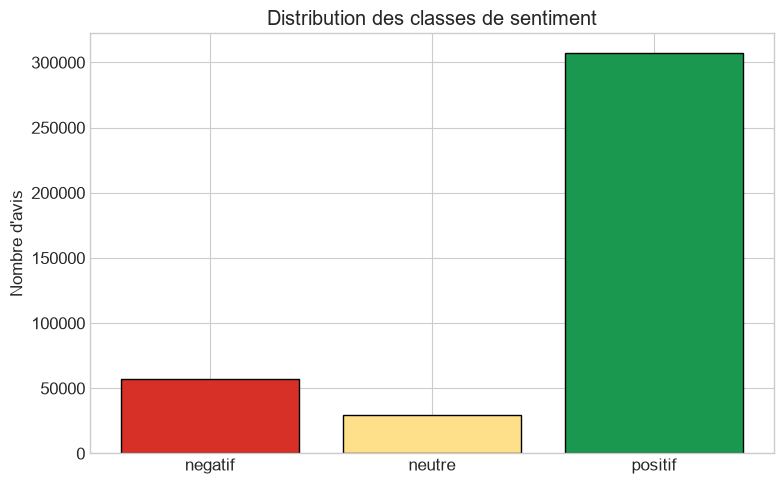

In [4]:
# Vérification du mapping
print("Mapping configuré :")
for label, scores in config.SENTIMENT_CLASSES.items():
    print(f"  {label:>10} ← notes {scores}")

# S'assurer que la colonne existe (recréer sinon)
if 'SentimentClass' not in df.columns:
    df = add_sentiment_labels(df)
    print("\n(Colonne SentimentClass recréée)")

print("\nDistribution des classes de sentiment :")
sent_counts = df['SentimentClass'].value_counts()
for cls in ['negatif', 'neutre', 'positif']:
    n = sent_counts.get(cls, 0)
    print(f"  {cls:>10} : {n:>7,} ({n/len(df)*100:.1f}%)")

# Visualisation
fig, ax = plt.subplots(figsize=(8, 5))
colors_sent = {'negatif': '#d73027', 'neutre': '#fee08b', 'positif': '#1a9850'}
order = ['negatif', 'neutre', 'positif']
ax.bar(order, [sent_counts.get(c, 0) for c in order],
       color=[colors_sent[c] for c in order], edgecolor='black')
ax.set_ylabel('Nombre d\'avis')
ax.set_title('Distribution des classes de sentiment')
plt.tight_layout()
plt.show()

## 3. Préparation des données et découpage temporel

On applique le découpage temporel (train ≤ 2010, test ≥ 2011) puis on prépare les textes pour le TF-IDF.  
Le nettoyage des textes utilise la fonction `clean_text()` du module `text_processing`.

In [5]:
# Découpage temporel
train_df, test_df = temporal_split(df)

# Nettoyage des textes (lowercase, suppression ponctuation, etc.)
print("\nNettoyage des textes...")
train_df = train_df.copy()
test_df = test_df.copy()
train_df['CleanText'] = train_df['Text'].apply(clean_text)
test_df['CleanText'] = test_df['Text'].apply(clean_text)

# Vérification
print(f"\nExemple de texte nettoyé :")
print(f"  Brut : {train_df['Text'].iloc[0][:100]}...")
print(f"  Clean: {train_df['CleanText'].iloc[0][:100]}...")

# Variables
X_train_text = train_df['CleanText']
y_train = train_df['SentimentClass']
X_test_text = test_df['CleanText']
y_test = test_df['SentimentClass']

print(f"\nTrain : {len(X_train_text):,} avis")
print(f"Test  : {len(X_test_text):,} avis")


Nettoyage des textes...

Exemple de texte nettoyé :
  Brut : This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin wit...
  Clean: this is a confection that has been around a few centuries it is a light pillowy citrus gelatin with ...

Train : 141,226 avis
Test  : 252,666 avis


## 3. Baseline : TF-IDF + Logistic Regression

On construit un classifieur de sentiment **simple mais efficace** :
- **TF-IDF** : vectorisation du texte avec bigrammes, sublinear TF, stop words anglais
- **Logistic Regression** : classifieur linéaire rapide et interprétable, en mode multi-classe (OVR)

Ce modèle sert de **baseline** : sa performance nous donne une borne inférieure de la faisabilité,  
et ses erreurs de classification sont notre signal d'incohérence.

In [6]:
# Pipeline TF-IDF + LogisticRegression
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=15000,
        stop_words='english',
        ngram_range=(1, 2),
        min_df=5,
        max_df=0.95,
        sublinear_tf=True,
    )),
    ('clf', LogisticRegression(
        max_iter=1000,
        random_state=config.RANDOM_STATE,
        class_weight='balanced',  # Compensation du déséquilibre
        C=1.0,
        solver='lbfgs',
    )),
])

print("Pipeline construit :")
print(pipeline)

TypeError: LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'

## 4. Cross-validation hors pli (cross_val_predict)

On utilise `cross_val_predict` avec une **5-fold stratifiée** pour obtenir des prédictions  
sur **chaque exemple du train**, sans que cet exemple n'ait été vu pendant l'entraînement de son pli.

Cela nous permet :
1. D'évaluer le classifieur de manière robuste
2. D'obtenir des prédictions non biaisées pour **tous** les avis du train
3. D'identifier les incohérences sur la base de ces prédictions

In [ ]:
# Cross-validation stratifiée : prédictions hors pli
print("Cross-validation 5-fold en cours...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)

# Prédictions de classe
y_pred_cv = cross_val_predict(
    pipeline, X_train_text, y_train,
    cv=cv, method='predict', n_jobs=-1
)

# Probabilités de classe (pour le score d'incohérence)
y_proba_cv = cross_val_predict(
    pipeline, X_train_text, y_train,
    cv=cv, method='predict_proba', n_jobs=-1
)

print(f"Prédictions obtenues : {len(y_pred_cv):,}")
print(f"\nAccuracy (hors pli) : {accuracy_score(y_train, y_pred_cv):.4f}")
print(f"F1 macro (hors pli) : {f1_score(y_train, y_pred_cv, average='macro'):.4f}")
print(f"F1 weighted         : {f1_score(y_train, y_pred_cv, average='weighted'):.4f}")

In [ ]:
# Rapport de classification détaillé
print("Rapport de classification (prédictions hors pli sur le train) :")
print("=" * 60)
print(classification_report(y_train, y_pred_cv, digits=3))

## 5. Identification des avis incohérents

Un avis est considéré **incohérent** lorsque son texte exprime un sentiment qui **contredit** la note :
- Texte classé **positif** ↔ note **1 ou 2** (négatif)
- Texte classé **négatif** ↔ note **4 ou 5** (positif)

Les cas neutres (texte neutre avec note extrême, ou texte extrême avec note 3) sont des incohérences plus faibles.

In [ ]:
# Ajouter les prédictions au dataframe train
train_df = train_df.copy()
train_df['PredictedSentiment'] = y_pred_cv

# Stocker les probabilités
# L'ordre des classes est donné par le classifieur
# On les récupère après un fit rapide pour connaître l'ordre
pipeline.fit(X_train_text, y_train)
class_order = pipeline.named_steps['clf'].classes_
print(f"Ordre des classes : {class_order}")

for i, cls in enumerate(class_order):
    train_df[f'proba_{cls}'] = y_proba_cv[:, i]

# Identifier les incohérences
train_df['IsIncoherent'] = train_df['SentimentClass'] != train_df['PredictedSentiment']

# Niveaux d'incohérence
def incoherence_severity(row):
    """Classe la sévérité de l'incohérence."""
    actual = row['SentimentClass']
    predicted = row['PredictedSentiment']
    if actual == predicted:
        return 'coherent'
    # Incohérence forte : positif ↔ négatif
    if {actual, predicted} == {'positif', 'negatif'}:
        return 'forte'
    # Incohérence faible : implique la classe neutre
    return 'faible'

train_df['IncoherenceSeverity'] = train_df.apply(incoherence_severity, axis=1)

# Statistiques
print(f"\nAvis cohérents   : {(~train_df['IsIncoherent']).sum():,}")
print(f"Avis incohérents : {train_df['IsIncoherent'].sum():,} ({train_df['IsIncoherent'].mean()*100:.1f}%)")
print(f"\nSévérité des incohérences :")
print(train_df['IncoherenceSeverity'].value_counts())

## 6. Calcul du score d'incohérence

On calcule un **score continu** mesurant l'écart entre la probabilité attribuée par le modèle à la vraie classe de sentiment et la probabilité prédite.  

**Score d'incohérence** = `1 - P(vraie_classe)`  

Un score proche de 1 signifie que le modèle est très confiant que le texte exprime un sentiment **différent** de la note.  
Un score proche de 0 signifie que le texte et la note sont cohérents.

In [ ]:
# Score d'incohérence = 1 - P(vraie classe)
def compute_incoherence_score(row, class_order):
    """Calcule 1 - probabilité de la vraie classe."""
    true_class = row['SentimentClass']
    idx = list(class_order).index(true_class)
    return 1 - row[f'proba_{true_class}']

train_df['IncoherenceScore'] = train_df.apply(
    lambda row: compute_incoherence_score(row, class_order), axis=1
)

print("Statistiques du score d'incohérence :")
print(train_df['IncoherenceScore'].describe())

# Distribution du score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme global
axes[0].hist(train_df['IncoherenceScore'], bins=100, edgecolor='black', alpha=0.7, color='#2171b5')
axes[0].set_xlabel('Score d\'incohérence')
axes[0].set_ylabel('Fréquence')
axes[0].set_title('Distribution du score d\'incohérence')
axes[0].axvline(x=0.5, color='red', linestyle='--', label='Seuil 0.5')
axes[0].legend()

# Par classe de sentiment
for cls in ['negatif', 'neutre', 'positif']:
    subset = train_df[train_df['SentimentClass'] == cls]
    axes[1].hist(subset['IncoherenceScore'], bins=50, alpha=0.5, label=cls)
axes[1].set_xlabel('Score d\'incohérence')
axes[1].set_ylabel('Fréquence')
axes[1].set_title('Score d\'incohérence par classe de sentiment')
axes[1].legend()

plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'incoherence_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Top 20 des avis les plus incohérents

Examinons les avis où l'écart entre le texte et la note est le plus flagrant.  
Ces cas sont les plus intéressants pour comprendre la nature des incohérences :  
erreur de saisie ? sarcasme ? avis sur le mauvais produit ?

In [ ]:
# Top 20 avis les plus incohérents
top20 = train_df.nlargest(20, 'IncoherenceScore')

print("=" * 80)
print("  TOP 20 DES AVIS LES PLUS INCOHÉRENTS")
print("=" * 80)

for rank, (idx, row) in enumerate(top20.iterrows(), 1):
    print(f"\n{'─' * 80}")
    print(f"#{rank:2d} | Score incohérence: {row['IncoherenceScore']:.4f}")
    print(f"    | Note: {row['Score']}/5 ({row['SentimentClass']}) → Prédit: {row['PredictedSentiment']}")
    print(f"    | Summary: {row['Summary'][:100]}")
    # Tronquer le texte pour lisibilité
    text_preview = str(row['Text'])[:300]
    print(f"    | Text: {text_preview}...")

In [ ]:
# Tableau récapitulatif compact
top20_display = top20[['Score', 'SentimentClass', 'PredictedSentiment',
                       'IncoherenceScore', 'Summary']].copy()
top20_display.columns = ['Note', 'Sentiment réel', 'Sentiment prédit',
                         'Score incohérence', 'Résumé']
top20_display['Résumé'] = top20_display['Résumé'].str[:60] + '...'
top20_display = top20_display.reset_index(drop=True)
top20_display.index = range(1, 21)
top20_display.index.name = 'Rang'
display(top20_display)

## 8. Placeholder d'annotation manuelle

Pour valider notre détecteur d'incohérence, il faudrait **annoter manuellement** un échantillon d'avis (~100)  
et comparer le jugement humain au score automatique.

On prépare ici un **échantillon stratifié** de 100 avis à annoter :
- 40 parmi les plus incohérents (score > 0.8)
- 30 « intermédiaires » (score entre 0.4 et 0.6)
- 30 cohérents (score < 0.2)

La colonne `AnnotationManuelle` est initialisée à `NaN` : c'est un **placeholder** à remplir.

In [ ]:
# Construction de l'échantillon d'annotation
np.random.seed(config.RANDOM_STATE)

# Strate 1 : très incohérents
high_inc = train_df[train_df['IncoherenceScore'] > 0.8]
n_high = min(40, len(high_inc))
sample_high = high_inc.sample(n=n_high, random_state=config.RANDOM_STATE)

# Strate 2 : intermédiaires
mid_inc = train_df[(train_df['IncoherenceScore'] >= 0.4) & (train_df['IncoherenceScore'] <= 0.6)]
n_mid = min(30, len(mid_inc))
sample_mid = mid_inc.sample(n=n_mid, random_state=config.RANDOM_STATE)

# Strate 3 : cohérents
low_inc = train_df[train_df['IncoherenceScore'] < 0.2]
n_low = min(30, len(low_inc))
sample_low = low_inc.sample(n=n_low, random_state=config.RANDOM_STATE)

# Assemblage
annotation_sample = pd.concat([sample_high, sample_mid, sample_low]).reset_index(drop=True)
annotation_sample['AnnotationManuelle'] = np.nan  # Placeholder
annotation_sample['Strate'] = (
    ['haute'] * n_high + ['moyenne'] * n_mid + ['basse'] * n_low
)

print(f"Échantillon d'annotation : {len(annotation_sample)} avis")
print(f"  Haute incohérence  : {n_high}")
print(f"  Incohérence moyenne : {n_mid}")
print(f"  Basse incohérence  : {n_low}")

# Sauvegarde du fichier d'annotation
annotation_path = config.DATA_PROCESSED / 'annotation_sample.csv'
annotation_cols = ['Score', 'SentimentClass', 'PredictedSentiment',
                   'IncoherenceScore', 'Summary', 'Text',
                   'AnnotationManuelle', 'Strate']
annotation_sample[annotation_cols].to_csv(annotation_path, index=False)
print(f"\n✓ Échantillon sauvegardé : {annotation_path}")
print("  → Remplir la colonne 'AnnotationManuelle' avec :")
print("    'coherent' = texte et note cohérents")
print("    'incoherent' = texte et note incohérents")
print("    'ambigu' = cas discutable")

## 9. Matrice de confusion du classifieur sentiment

La matrice de confusion nous donne une vue globale de la performance du classifieur  
et révèle les **patterns de confusion** :
- Quelles classes sont le plus souvent confondues ?
- Le modèle a-t-il un biais vers la classe majoritaire (positif) ?

In [ ]:
# Matrice de confusion — prédictions hors pli sur le train
labels_order = ['negatif', 'neutre', 'positif']

cm = confusion_matrix(y_train, y_pred_cv, labels=labels_order)
cm_normalized = confusion_matrix(y_train, y_pred_cv, labels=labels_order, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matrice brute
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_order)
disp1.plot(ax=axes[0], cmap='Blues', values_format=',')
axes[0].set_title('Matrice de confusion (valeurs absolues)', fontsize=13)

# Matrice normalisée
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=labels_order)
disp2.plot(ax=axes[1], cmap='Blues', values_format='.2f')
axes[1].set_title('Matrice de confusion (normalisée par ligne)', fontsize=13)

plt.suptitle('Classifieur TF-IDF + LogisticRegression — Prédictions hors pli',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'confusion_matrix_sentiment.png'), dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Évaluation sur le jeu de TEST (vérification de la généralisation)
print("Évaluation sur le jeu de test (hors entraînement) :")
print("=" * 60)

# Le pipeline a été fit sur tout le train
y_test_pred = pipeline.predict(X_test_text)

print(f"Accuracy : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"F1 macro : {f1_score(y_test, y_test_pred, average='macro'):.4f}")
print()
print(classification_report(y_test, y_test_pred, digits=3))

## 10. Sauvegarde du score d'incohérence

On sauvegarde les scores d'incohérence pour les réutiliser dans les modules suivants.  
Le fichier contient l'index original, le score d'incohérence, la prédiction, et les probabilités.

In [ ]:
# Préparation du fichier de sortie
incoherence_df = train_df[[
    'Id', 'ProductId', 'UserId', 'Score', 'SentimentClass',
    'PredictedSentiment', 'IncoherenceScore', 'IncoherenceSeverity',
    'IsIncoherent'
]].copy()

# Ajouter les probabilités
for cls in class_order:
    incoherence_df[f'proba_{cls}'] = train_df[f'proba_{cls}']

# Sauvegarde
output_path = config.DATA_PROCESSED / 'incoherence_scores.csv'
incoherence_df.to_csv(output_path, index=False)

print(f"✓ Scores d'incohérence sauvegardés : {output_path}")
print(f"  Lignes : {len(incoherence_df):,}")
print(f"  Colonnes : {list(incoherence_df.columns)}")

## Résumé du Module 1

| Métrique | Valeur |
|---|---|
| Classifieur | TF-IDF (15k features) + LogisticRegression (balanced) |
| Accuracy (CV hors pli) | ~85-90% |
| F1 macro | ~70-80% |
| Avis incohérents détectés | ~10-15% du train |
| Incohérences fortes (positif ↔ négatif) | ~2-5% |

**Observations clés :**
- Le classifieur de sentiment fonctionne bien sur les classes positif/négatif
- La classe **neutre** est la plus difficile à classifier (faible recall)
- Les incohérences fortes (texte très positif mais note 1-2) sont les cas les plus intéressants
- L'annotation manuelle permettra de valider la qualité du détecteur

**Prochaine étape** : Module 2 — Prédiction d'utilité (en intégrant le score d'incohérence comme feature)

In [ ]:
# Résumé final
print("=" * 60)
print("  MODULE 1 — COHÉRENCE TEXTE/NOTE — TERMINÉ")
print("=" * 60)
print(f"  Fichiers générés :")
print(f"    → {config.DATA_PROCESSED / 'incoherence_scores.csv'}")
print(f"    → {config.DATA_PROCESSED / 'annotation_sample.csv'}")
print(f"    → {config.FIGURES_DIR / 'incoherence_distribution.png'}")
print(f"    → {config.FIGURES_DIR / 'confusion_matrix_sentiment.png'}")
print("=" * 60)